In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from IPython.display import display

sns.set_theme(style="whitegrid")

# Google Colab: upload clean_dataset.csv when prompted
try:
    from google.colab import files
    uploaded = files.upload()
    file_name = next(iter(uploaded))
except ImportError:
    file_name = "clean_dataset.csv"

df = pd.read_csv(file_name)

# Convert expected numeric/date columns safely
for col in ["quantity", "unit_price", "discount_pct", "gross_sales", "discount_amount", "net_sales"]:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")
if "order_date" in df.columns:
    df["order_date"] = pd.to_datetime(df["order_date"], errors="coerce")

print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())
display(df.head())

Saving retail-orders-raw.csv to retail-orders-raw (1).csv
Dataset shape: (12, 9)
Columns: ['order_id', 'order_date', 'customer_segment', 'city', 'category', 'quantity', 'unit_price', 'discount_pct', 'payment_status']


,order_id,order_date,customer_segment,city,category,quantity,unit_price,discount_pct,payment_status
0,RT-1001,2026-01-03,Student,Chennai,Learning Kit,2.0,799,10.0,Paid
1,RT-1002,NaT,Fresher,Bengaluru,Course Access,1.0,1499,0.0,paid
2,RT-1003,2026-01-05,student,Chennai,Course Access,1.0,1499,NaN,Pending
3,RT-1004,2026-01-07,Professional,Hyderabad,Learning Kit,3.0,799,5.0,Paid
4,RT-1004,2026-01-07,Professional,Hyderabad,Learning Kit,3.0,799,5.0,Paid


In [2]:
print("Rows and columns:", df.shape)
print("\nData types:")
print(df.dtypes)
print("\nMissing values:")
print(df.isna().sum())
print("\nDuplicate rows:", df.duplicated().sum())
print("\nUnique order IDs:", df["order_id"].nunique() if "order_id" in df.columns else "N/A")

Rows and columns: (12, 9)

Data types:
order_id                    object
order_date          datetime64[ns]
customer_segment            object
city                        object
category                    object
quantity                   float64
unit_price                   int64
discount_pct               float64
payment_status              object
dtype: object

Missing values:
order_id            0
order_date          3
customer_segment    0
city                1
category            0
quantity            1
unit_price          0
discount_pct        1
payment_status      0
dtype: int64

Duplicate rows: 1

Unique order IDs: 11


In [3]:
numeric_cols = df.select_dtypes(include=np.number).columns.tolist()
desc = df[numeric_cols].describe().T
desc["median"] = df[numeric_cols].median()
display(desc[["count", "mean", "median", "std", "min", "25%", "50%", "75%", "max"]].round(2))

,count,mean,median,std,min,25%,50%,75%,max
quantity,11.0,1.45,1.0,1.13,-1.0,1.0,1.0,2.0,3.0
unit_price,12.0,1082.33,999.0,318.61,799.0,799.0,999.0,1499.0,1499.0
discount_pct,11.0,13.64,5.0,30.75,0.0,0.0,5.0,10.0,105.0


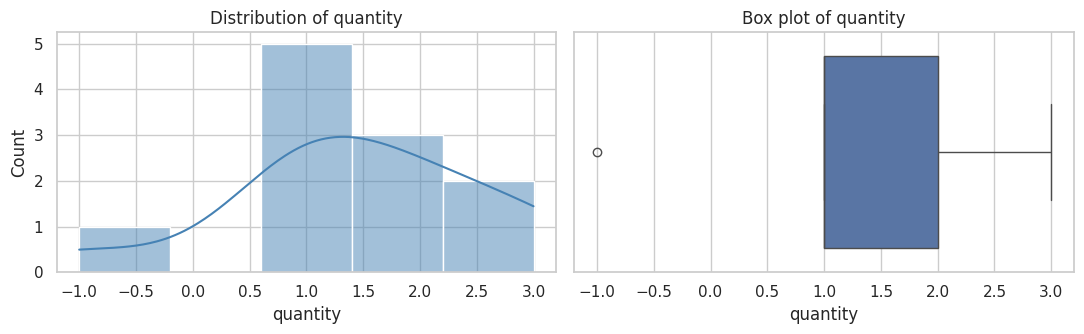

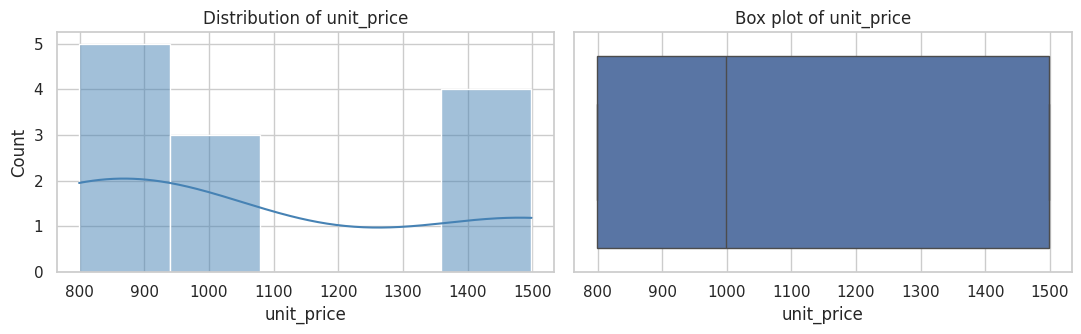

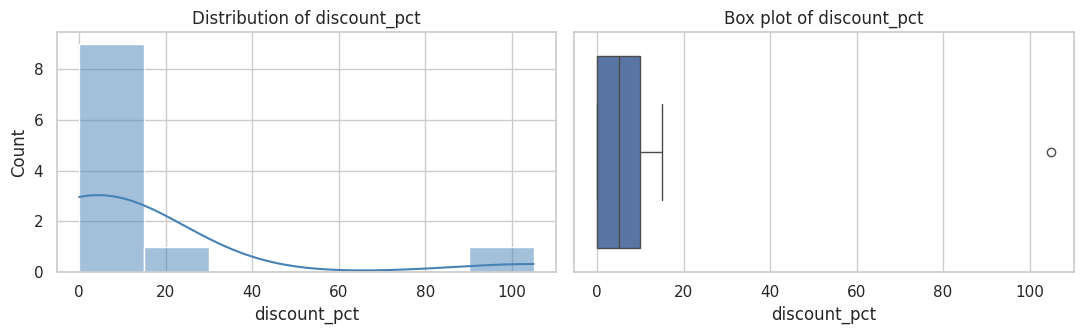

In [4]:
plot_cols = [c for c in ["quantity", "unit_price", "discount_pct", "gross_sales", "net_sales"] if c in df.columns]

for col in plot_cols:
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
    sns.histplot(df[col].dropna(), kde=True, ax=axes[0], color="steelblue")
    axes[0].set_title(f"Distribution of {col}")
    axes[0].set_xlabel(col)
    sns.boxplot(x=df[col], ax=axes[1])
    axes[1].set_title(f"Box plot of {col}")
    plt.tight_layout()
    plt.show()

,quantity,unit_price,discount_pct
quantity,1.00,-0.10,0.16
unit_price,-0.10,1.00,-0.06
discount_pct,0.16,-0.06,1.00


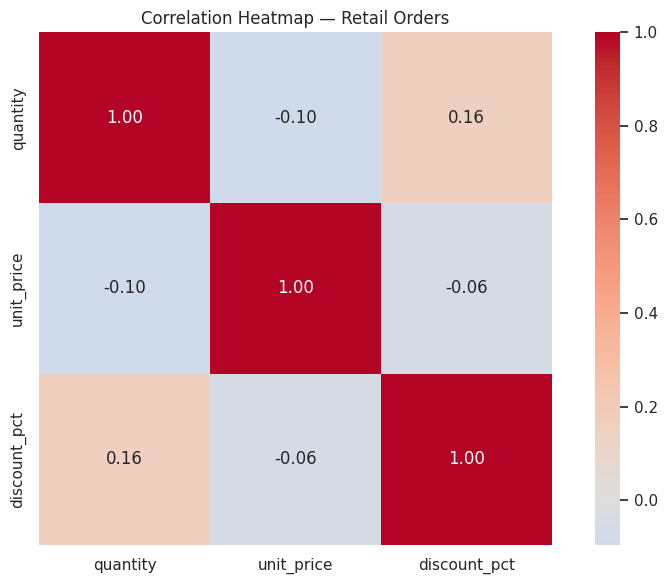

In [5]:
corr_cols = [c for c in ["quantity", "unit_price", "discount_pct", "gross_sales", "discount_amount", "net_sales"] if c in df.columns]
corr = df[corr_cols].corr(method="pearson")
display(corr.round(2))
plt.figure(figsize=(9, 6))
sns.heatmap(corr, annot=True, cmap="coolwarm", center=0, fmt=".2f", square=True)
plt.title("Correlation Heatmap — Retail Orders")
plt.tight_layout()
plt.show()

In [16]:
import numpy as np
import pandas as pd
from scipy import stats

In [18]:
print(df.columns.tolist())

['order_id', 'order_date', 'customer_segment', 'city', 'category', 'quantity', 'unit_price', 'discount_pct', 'payment_status']


In [19]:
for col in df.columns:
    print(col)

order_id
order_date
customer_segment
city
category
quantity
unit_price
discount_pct
payment_status


In [20]:
df.columns = df.columns.str.strip()

In [21]:
print(df.columns.tolist())

['order_id', 'order_date', 'customer_segment', 'city', 'category', 'quantity', 'unit_price', 'discount_pct', 'payment_status']


In [22]:
required = [
    "discount_pct",
    "net_sales",
    "quantity",
    "gross_sales",
    "payment_status"
]

for col in required:
    print(col, "->", col in df.columns)

discount_pct -> True
net_sales -> False
quantity -> True
gross_sales -> False
payment_status -> True


In [23]:
for col in df.columns:
    if "sales" in col.lower() or "amount" in col.lower() or "revenue" in col.lower():
        print(col)

In [24]:
print("ALL DATASET COLUMNS:")
for i, col in enumerate(df.columns):
    print(i, ":", col)

ALL DATASET COLUMNS:
0 : order_id
1 : order_date
2 : customer_segment
3 : city
4 : category
5 : quantity
6 : unit_price
7 : discount_pct
8 : payment_status


In [25]:
display(df.head())

,order_id,order_date,customer_segment,city,category,quantity,unit_price,discount_pct,payment_status
0,RT-1001,2026-01-03,Student,Chennai,Learning Kit,2.0,799,10.0,Paid
1,RT-1002,NaT,Fresher,Bengaluru,Course Access,1.0,1499,0.0,paid
2,RT-1003,2026-01-05,student,Chennai,Course Access,1.0,1499,NaN,Pending
3,RT-1004,2026-01-07,Professional,Hyderabad,Learning Kit,3.0,799,5.0,Paid
4,RT-1004,2026-01-07,Professional,Hyderabad,Learning Kit,3.0,799,5.0,Paid


In [26]:
import numpy as np
import pandas as pd
from scipy import stats

# Clean column names
df.columns = df.columns.astype(str).str.strip()

# Display dataset columns
print("Dataset Columns:", df.columns.tolist())


# Automatically identify columns
def find_column(possible_names):
    for name in possible_names:
        for col in df.columns:
            if col.lower().strip() == name.lower():
                return col
    return None


discount_col = find_column(["discount_pct", "discount_percent", "discount"])
quantity_col = find_column(["quantity", "qty", "order_quantity"])
payment_col = find_column(["payment_status", "payment", "status"])

net_col = find_column(["net_sales", "net_amount", "net_revenue",
                       "total_amount", "final_amount"])

gross_col = find_column(["gross_sales", "gross_amount",
                         "gross_revenue", "sales_amount"])

price_col = find_column(["unit_price", "price", "selling_price"])


# Convert numeric columns
def numeric_column(col):
    if col is None:
        return None
    return pd.to_numeric(df[col], errors="coerce")


# Calculate sales if required columns are available
quantity = numeric_column(quantity_col)
price = numeric_column(price_col)
discount = numeric_column(discount_col)

if gross_col is None and quantity is not None and price is not None:
    df["_calculated_gross_sales"] = quantity * price
    gross_col = "_calculated_gross_sales"

if net_col is None and gross_col is not None:
    gross = numeric_column(gross_col)

    if discount is not None:
        # Assumes discount is expressed as a percentage
        discount_rate = discount.copy()
        if discount_rate.dropna().max() > 1:
            discount_rate = discount_rate / 100

        df["_calculated_net_sales"] = gross * (1 - discount_rate)
    else:
        df["_calculated_net_sales"] = gross

    net_col = "_calculated_net_sales"


# Spearman correlation test
def spearman_test(x, y):
    pair = pd.DataFrame({
        "x": x,
        "y": y
    }).dropna()

    if len(pair) < 3 or pair["x"].nunique() < 2 or pair["y"].nunique() < 2:
        return len(pair), np.nan, np.nan

    result = stats.spearmanr(
        pair["x"],
        pair["y"],
        alternative="greater"
    )

    return len(pair), result.statistic, result.pvalue


# H1: Discount percentage vs Net sales
if discount_col and net_col:
    h1 = spearman_test(
        numeric_column(discount_col),
        numeric_column(net_col)
    )
else:
    h1 = (0, np.nan, np.nan)


# H2: Quantity vs Gross sales
if quantity_col and gross_col:
    h2 = spearman_test(
        numeric_column(quantity_col),
        numeric_column(gross_col)
    )
else:
    h2 = (0, np.nan, np.nan)


# H3: Paid orders vs Non-paid orders
if payment_col and net_col:
    payment = df[payment_col].astype(str).str.strip().str.lower()
    sales = numeric_column(net_col)

    paid = sales[payment == "paid"].dropna()
    nonpaid = sales[payment != "paid"].dropna()

    if len(paid) > 0 and len(nonpaid) > 0:
        h3_result = stats.mannwhitneyu(
            paid,
            nonpaid,
            alternative="greater"
        )

        h3 = {
            "Paid orders": len(paid),
            "Non-paid orders": len(nonpaid),
            "U statistic": h3_result.statistic,
            "p-value": h3_result.pvalue
        }
    else:
        h3 = {
            "Paid orders": len(paid),
            "Non-paid orders": len(nonpaid),
            "U statistic": np.nan,
            "p-value": np.nan
        }
else:
    h3 = {
        "Paid orders": 0,
        "Non-paid orders": 0,
        "U statistic": np.nan,
        "p-value": np.nan
    }


# Display results
results = pd.DataFrame([
    {
        "Hypothesis": "H1: Discount vs Net Sales",
        "N": h1[0],
        "Correlation": h1[1],
        "P-value": h1[2]
    },
    {
        "Hypothesis": "H2: Quantity vs Gross Sales",
        "N": h2[0],
        "Correlation": h2[1],
        "P-value": h2[2]
    }
])

print("\nHYPOTHESIS TESTING RESULTS")
display(results)

print("\nH3: Paid vs Non-paid Orders")
display(pd.DataFrame([h3]))


# Statistical interpretation
print("\nSTATISTICAL INTERPRETATION")

for label, result in [("H1", h1), ("H2", h2)]:
    if pd.notna(result[2]):
        print(
            f"{label}: p-value = {result[2]:.4f} - "
            f"{'Significant' if result[2] < 0.05 else 'Not Significant'}"
        )
    else:
        print(f"{label}: Could not be tested reliably.")

p3 = h3["p-value"]

if pd.notna(p3):
    print(
        f"H3: p-value = {p3:.4f} - "
        f"{'Significant' if p3 < 0.05 else 'Not Significant'}"
    )
else:
    print("H3: Could not be tested reliably.")

Dataset Columns: ['order_id', 'order_date', 'customer_segment', 'city', 'category', 'quantity', 'unit_price', 'discount_pct', 'payment_status']

HYPOTHESIS TESTING RESULTS


,Hypothesis,N,Correlation,P-value
0,H1: Discount vs Net Sales,10,0.012665,0.486150
1,H2: Quantity vs Gross Sales,11,0.899341,0.000082



H3: Paid vs Non-paid Orders


,Paid orders,Non-paid orders,U statistic,p-value
0,8,2,4.5,0.853337



STATISTICAL INTERPRETATION
H1: p-value = 0.4862 - Not Significant
H2: p-value = 0.0001 - Significant
H3: p-value = 0.8533 - Not Significant


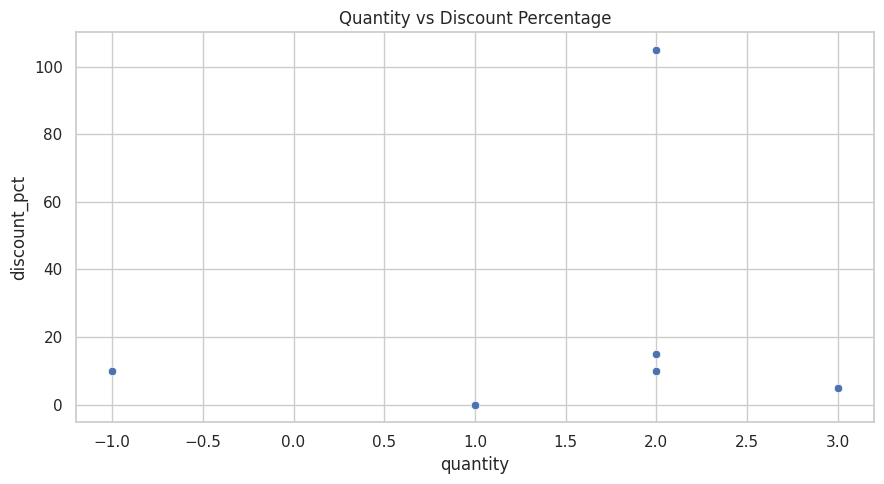

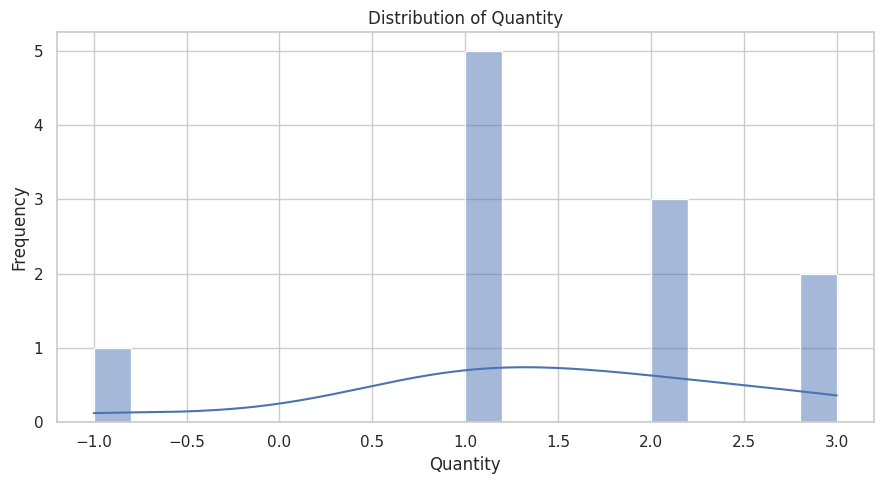

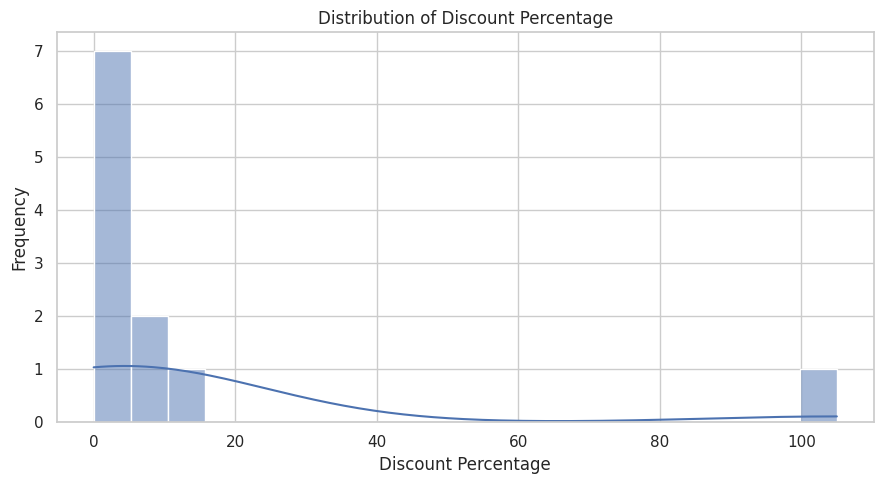

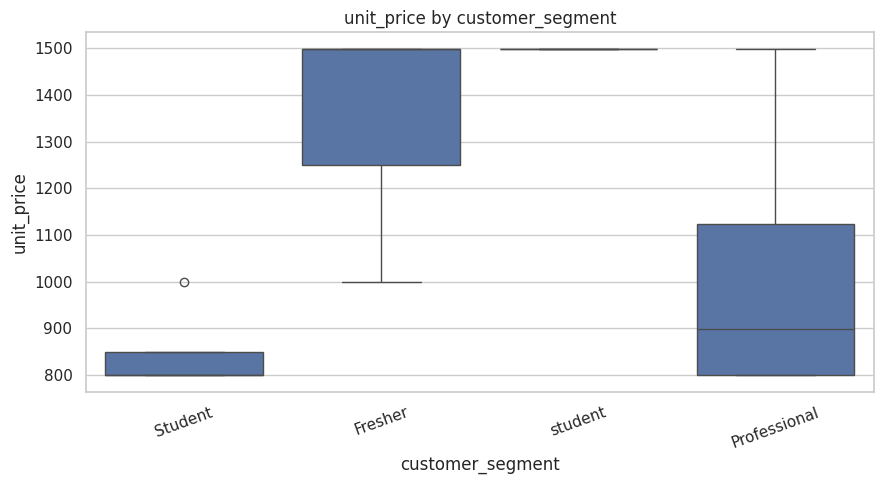

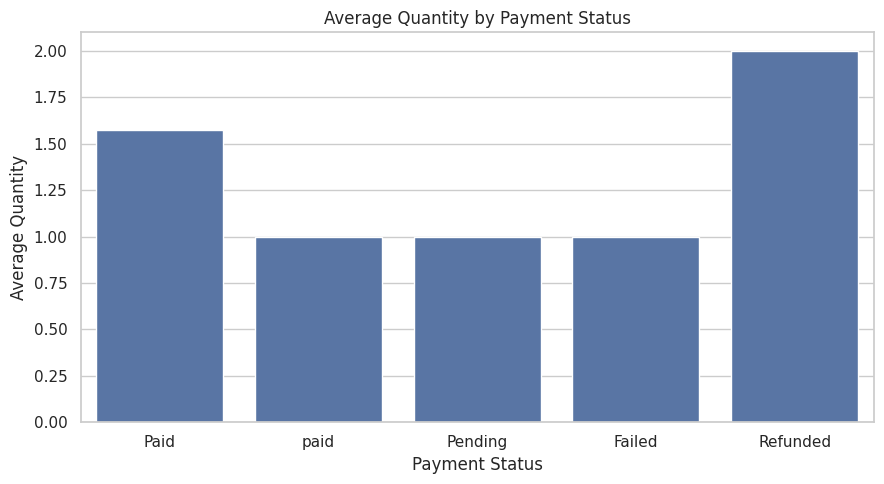

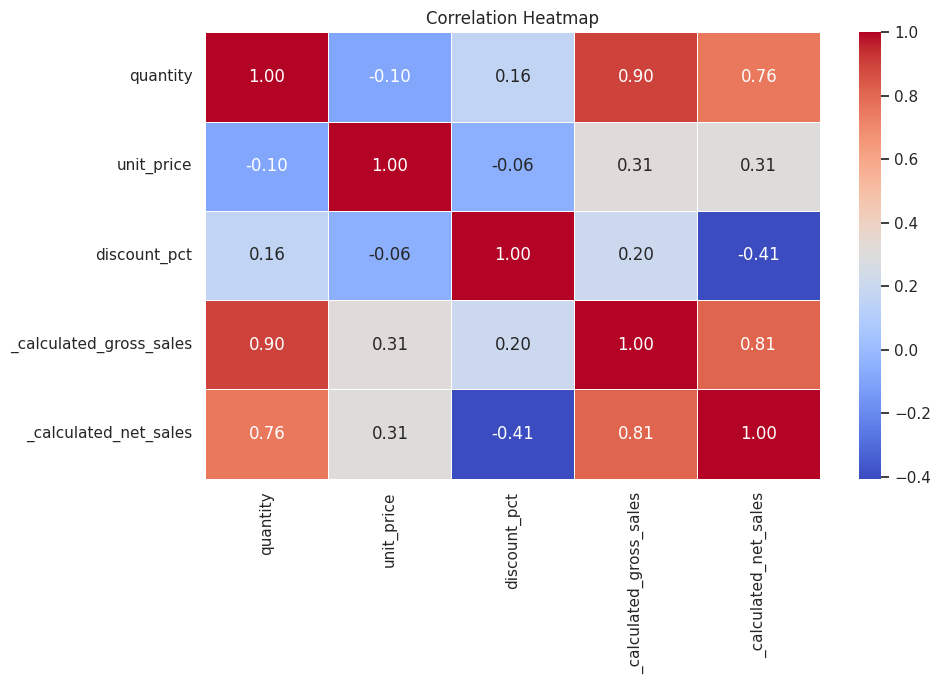

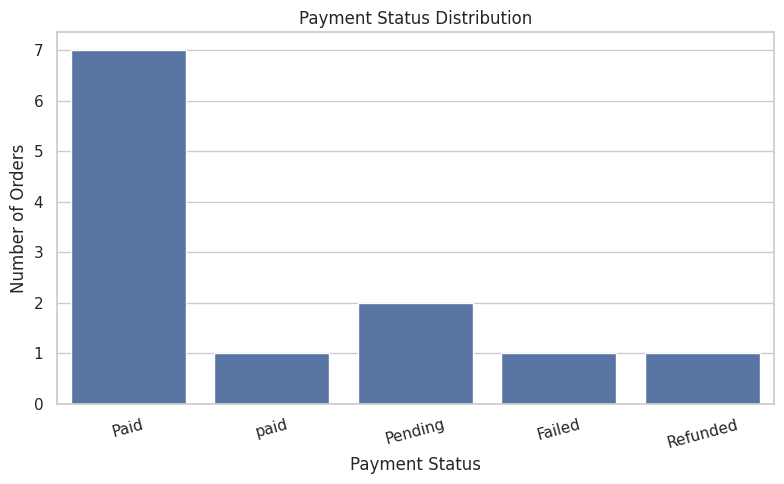

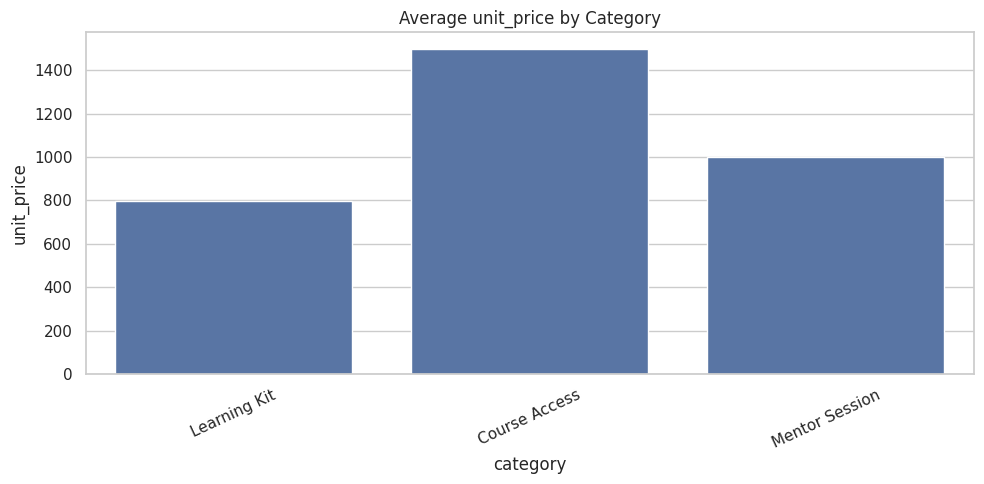

EDA Visualization Completed!


In [27]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# Clean column names
df.columns = df.columns.astype(str).str.strip()

# Convert important columns to numeric if available
for col in ["quantity", "discount_pct", "unit_price",
            "net_sales", "gross_sales"]:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")

# Identify available columns
numeric_cols = df.select_dtypes(include=np.number).columns.tolist()

# 1. Scatter Plot
plt.figure(figsize=(9, 5))

if "quantity" in df.columns and "net_sales" in df.columns:
    sns.scatterplot(data=df, x="quantity", y="net_sales")
    plt.title("Net Sales vs Quantity")

elif "quantity" in df.columns and "discount_pct" in df.columns:
    sns.scatterplot(data=df, x="quantity", y="discount_pct")
    plt.title("Quantity vs Discount Percentage")

elif len(numeric_cols) >= 2:
    sns.scatterplot(data=df, x=numeric_cols[0], y=numeric_cols[1])
    plt.title(f"{numeric_cols[0]} vs {numeric_cols[1]}")

plt.tight_layout()
plt.show()


# 2. Quantity Distribution
if "quantity" in df.columns:
    plt.figure(figsize=(9, 5))
    sns.histplot(df["quantity"].dropna(), bins=20, kde=True)
    plt.title("Distribution of Quantity")
    plt.xlabel("Quantity")
    plt.ylabel("Frequency")
    plt.tight_layout()
    plt.show()


# 3. Discount Distribution
if "discount_pct" in df.columns:
    plt.figure(figsize=(9, 5))
    sns.histplot(df["discount_pct"].dropna(), bins=20, kde=True)
    plt.title("Distribution of Discount Percentage")
    plt.xlabel("Discount Percentage")
    plt.ylabel("Frequency")
    plt.tight_layout()
    plt.show()


# 4. Box Plot: Customer Segment or Payment Status
group_col = next(
    (c for c in ["customer_segment", "category", "payment_status"]
     if c in df.columns),
    None
)

value_col = next(
    (c for c in ["net_sales", "gross_sales", "unit_price", "quantity"]
     if c in df.columns),
    None
)

if group_col and value_col:
    plt.figure(figsize=(9, 5))
    sns.boxplot(data=df, x=group_col, y=value_col)
    plt.title(f"{value_col} by {group_col}")
    plt.xticks(rotation=20)
    plt.tight_layout()
    plt.show()


# 5. Bar Chart: Average Quantity by Payment Status
if "payment_status" in df.columns and "quantity" in df.columns:
    plt.figure(figsize=(9, 5))
    sns.barplot(
        data=df,
        x="payment_status",
        y="quantity",
        estimator="mean",
        errorbar=None
    )
    plt.title("Average Quantity by Payment Status")
    plt.xlabel("Payment Status")
    plt.ylabel("Average Quantity")
    plt.tight_layout()
    plt.show()


# 6. Correlation Heatmap
if len(numeric_cols) >= 2:
    plt.figure(figsize=(10, 7))

    correlation = df[numeric_cols].corr()

    sns.heatmap(
        correlation,
        annot=True,
        cmap="coolwarm",
        fmt=".2f",
        linewidths=0.5
    )

    plt.title("Correlation Heatmap")
    plt.tight_layout()
    plt.show()


# 7. Payment Status Distribution
if "payment_status" in df.columns:
    plt.figure(figsize=(8, 5))

    sns.countplot(
        data=df,
        x="payment_status"
    )

    plt.title("Payment Status Distribution")
    plt.xlabel("Payment Status")
    plt.ylabel("Number of Orders")
    plt.xticks(rotation=15)
    plt.tight_layout()
    plt.show()


# 8. Category-wise Average Sales (if available)
if "category" in df.columns:
    sales_col = next(
        (c for c in ["net_sales", "gross_sales", "unit_price"]
         if c in df.columns),
        None
    )

    if sales_col:
        plt.figure(figsize=(10, 5))

        sns.barplot(
            data=df,
            x="category",
            y=sales_col,
            estimator="mean",
            errorbar=None
        )

        plt.title(f"Average {sales_col} by Category")
        plt.xticks(rotation=25)
        plt.tight_layout()
        plt.show()


print("EDA Visualization Completed!")

Exact duplicate rows removed: 1

CLEANED DATA


,order_id,order_date,customer_segment,city,category,quantity,unit_price,discount_pct,payment_status,_calculated_gross_sales,_calculated_net_sales,gross_sales,net_sales
0,RT-1001,2026-01-03,Student,Chennai,Learning Kit,2.0,799.0,10.0,paid,1598.0,1438.20,1598.0,1438.20
1,RT-1002,NaT,Fresher,Bengaluru,Course Access,1.0,1499.0,0.0,paid,1499.0,1499.00,1499.0,1499.00
2,RT-1003,2026-01-05,Student,Chennai,Course Access,1.0,1499.0,NaN,pending,1499.0,NaN,1499.0,NaN
3,RT-1004,2026-01-07,Professional,Hyderabad,Learning Kit,3.0,799.0,5.0,paid,2397.0,2277.15,2397.0,2277.15
5,RT-1005,2026-01-09,Fresher,<NA>,Mentor Session,1.0,999.0,0.0,failed,999.0,999.00,999.0,999.00
6,RT-1006,NaT,Student,Pune,Learning Kit,NaN,799.0,10.0,paid,-799.0,-719.10,NaN,NaN
7,RT-1007,2026-01-12,Professional,Mumbai,Mentor Session,2.0,999.0,NaN,paid,1998.0,-99.90,1998.0,NaN
8,RT-1008,2026-01-14,Fresher,Bengaluru,Course Access,NaN,1499.0,0.0,pending,NaN,NaN,NaN,NaN
9,RT-1009,2026-01-16,Student,Chennai,Learning Kit,1.0,799.0,0.0,paid,799.0,799.00,799.0,799.00
10,RT-1010,2026-01-18,Professional,Delhi,Course Access,2.0,1499.0,15.0,refunded,2998.0,2548.30,2998.0,2548.30



DATA QUALITY REPORT
order_id                   0
order_date                 3
customer_segment           0
city                       1
category                   0
quantity                   2
unit_price                 0
discount_pct               2
payment_status             0
_calculated_gross_sales    1
_calculated_net_sales      2
gross_sales                2
net_sales                  4
dtype: int64

DESCRIPTIVE STATISTICS


,count,mean,std,min,25%,50%,75%,max
quantity,9.0,1.555556,0.726483,1.0,1.0,1.0,2.000,3.0
unit_price,11.0,1108.090909,320.794468,799.0,799.0,999.0,1499.000,1499.0
discount_pct,9.0,4.444444,5.833333,0.0,0.0,0.0,10.000,15.0
gross_sales,9.0,1642.888889,717.275304,799.0,999.0,1499.0,1998.000,2998.0
net_sales,7.0,1508.521429,670.771937,799.0,999.0,1438.2,1888.075,2548.3


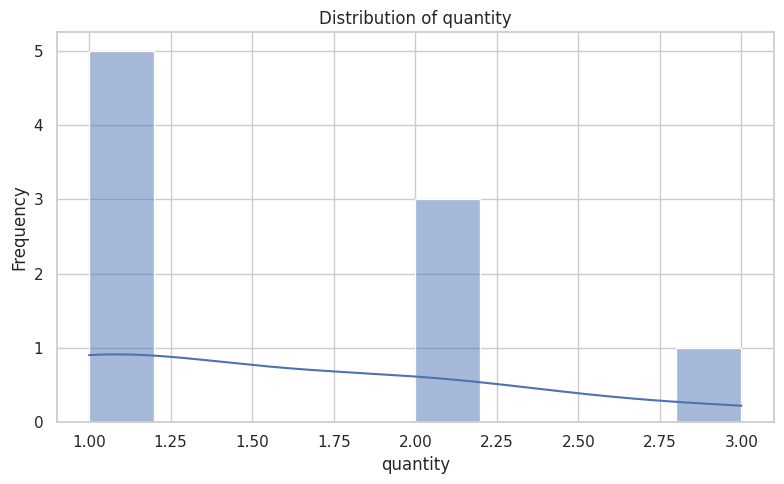

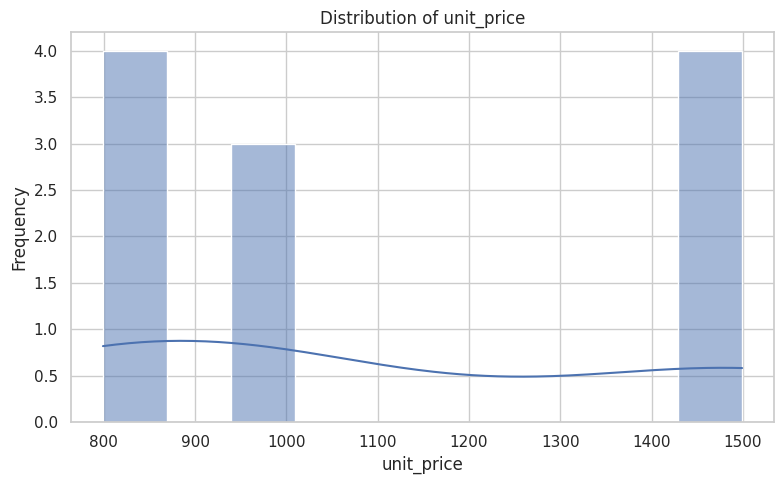

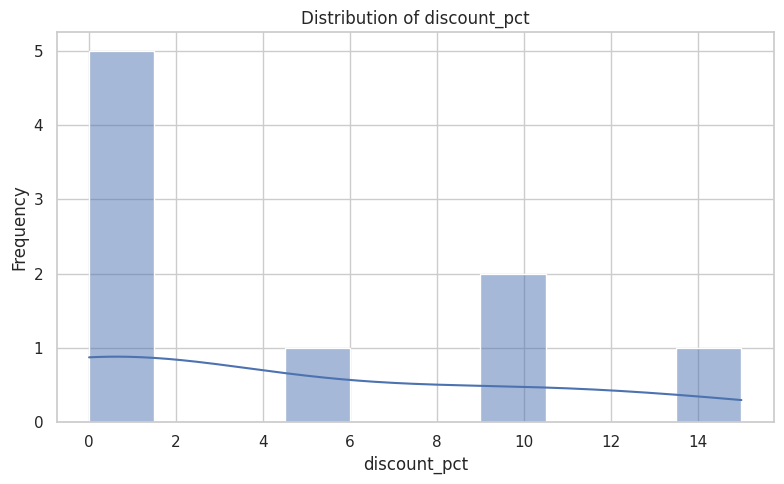

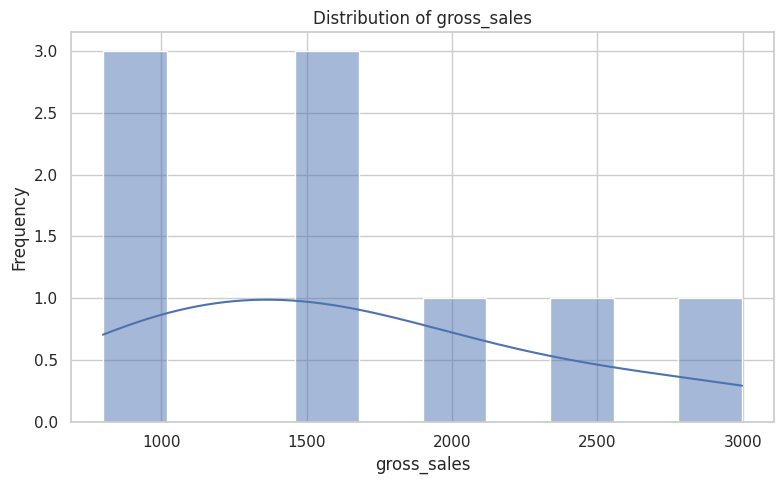

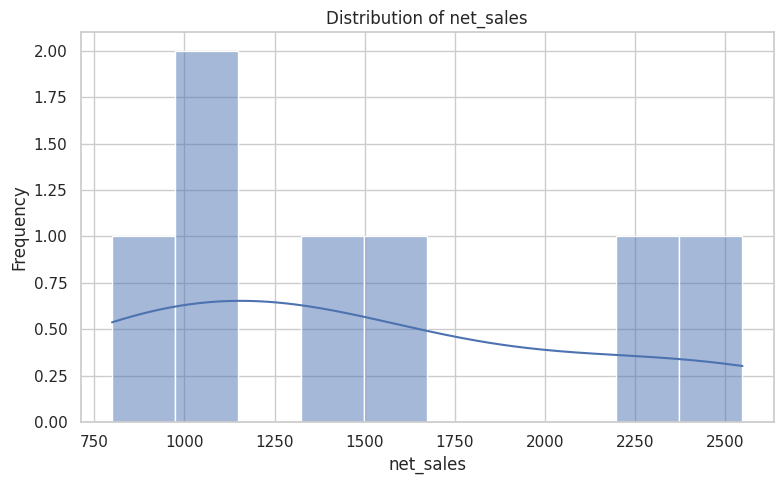

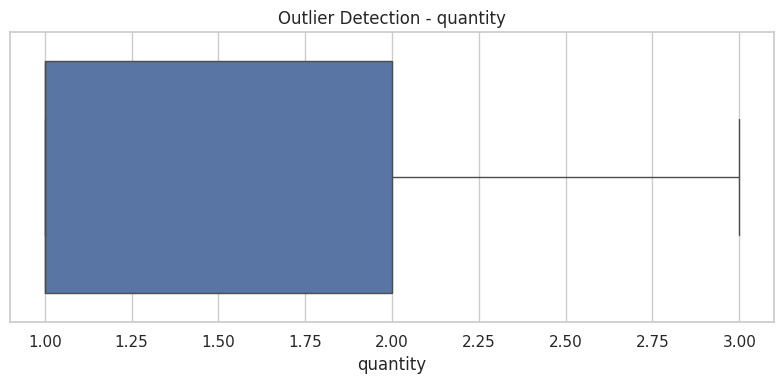

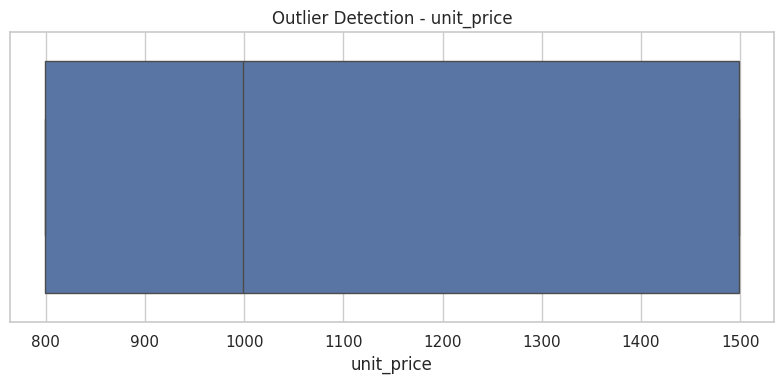

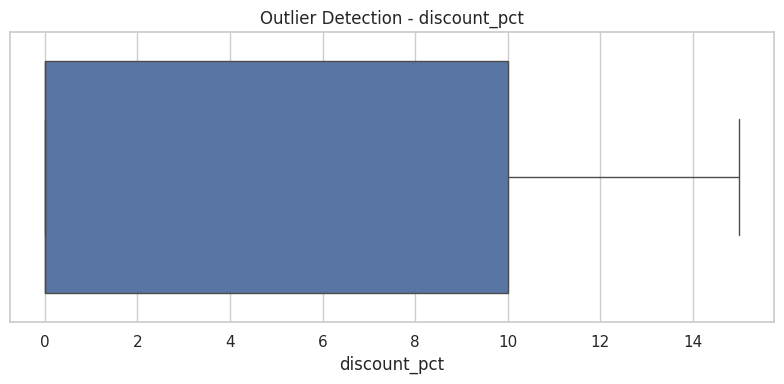

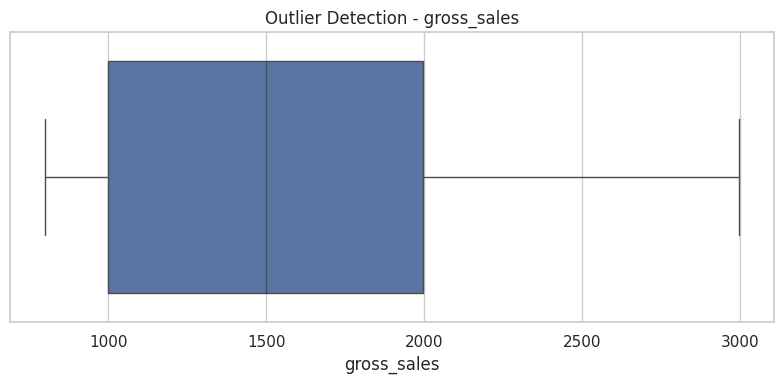

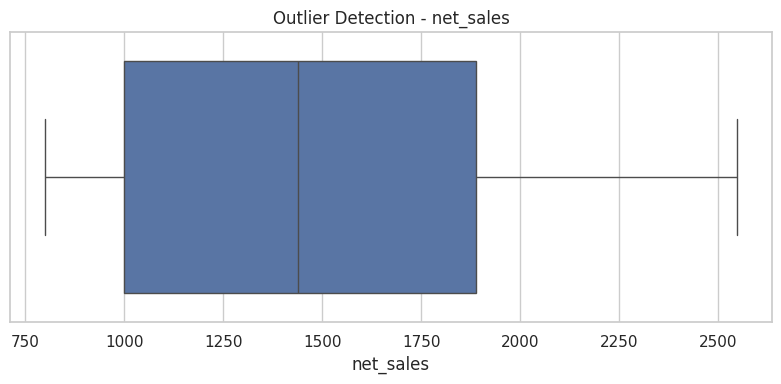

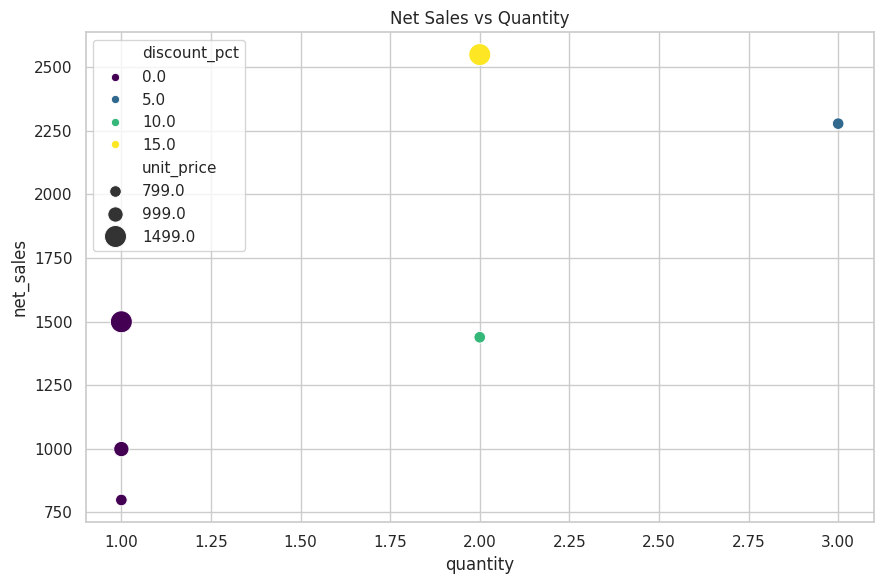

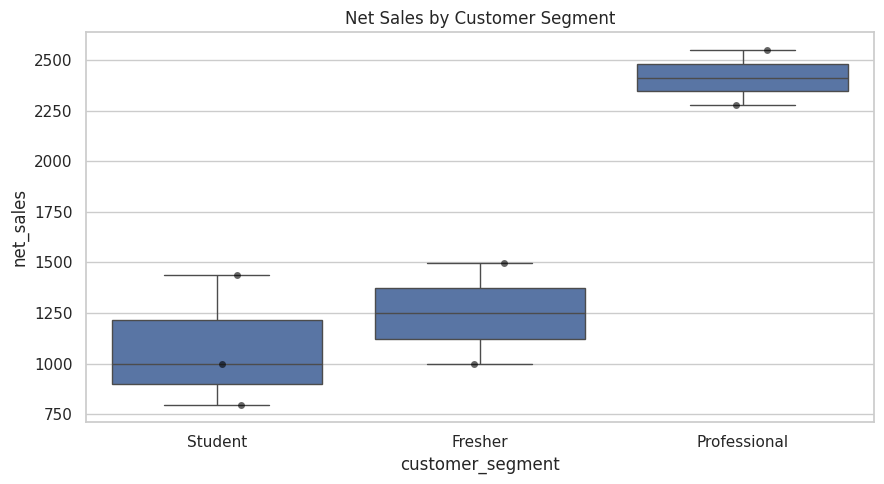

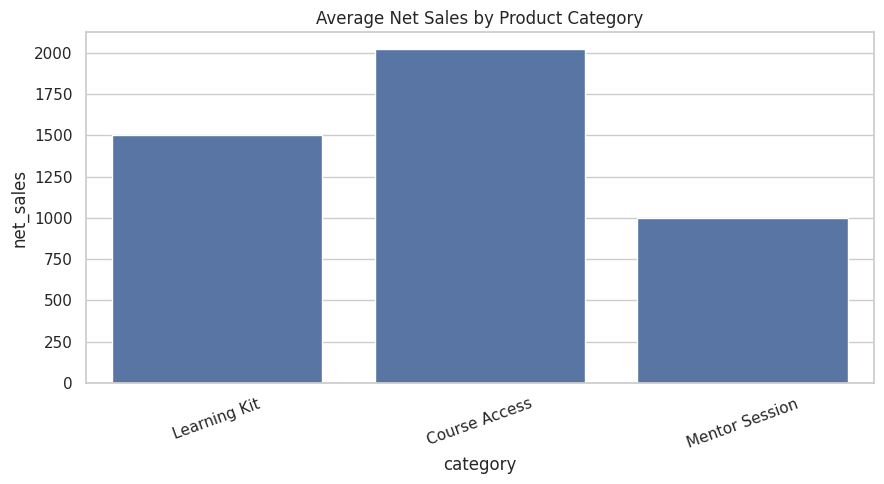

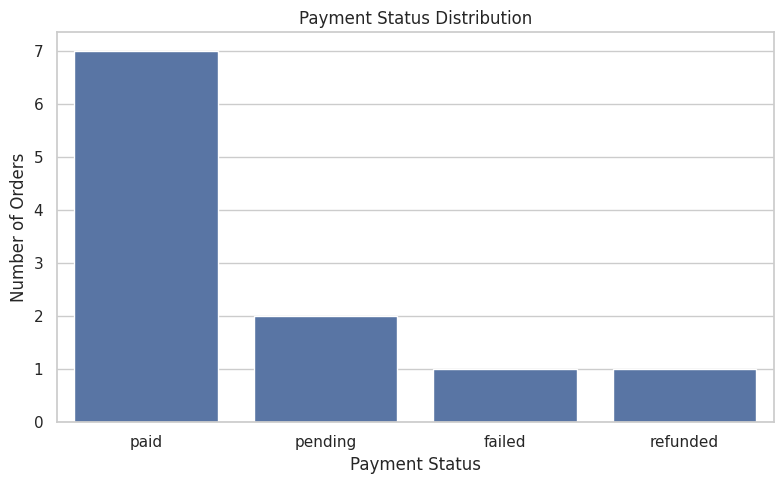

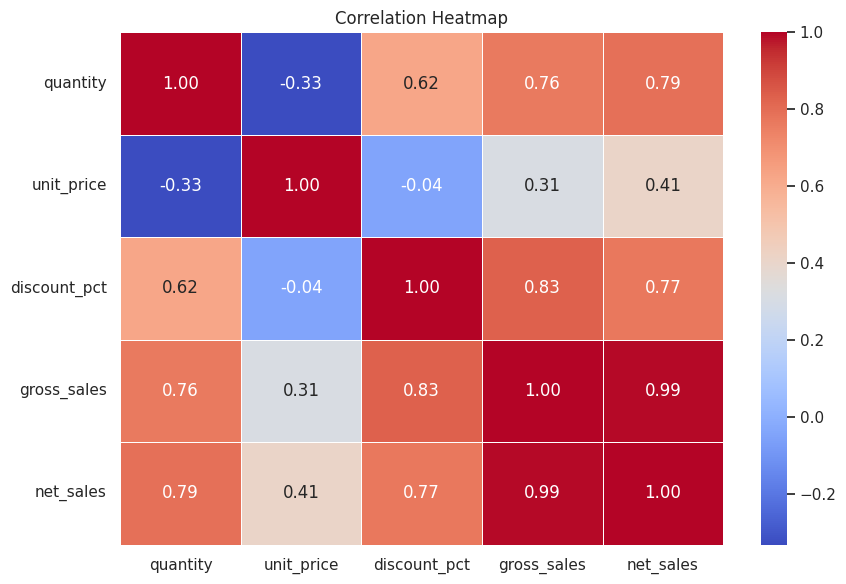


HYPOTHESIS TEST RESULTS


,Hypothesis,N,Correlation,P_value
0,H1: Discount vs Net Sales,7,0.735600,0.059518
1,H2: Quantity vs Gross Sales,9,0.864393,0.001321



H3: PAID VS NON-PAID ORDERS


,Paid_n,Nonpaid_n,U,p_value
0,5,2,3.5,0.782777



STATISTICAL INTERPRETATION
H1 p-value: 0.0595 | Not significant
H2 p-value: 0.0013 | Significant
H3 p-value: 0.7828 | Not significant

TOP 5 BUSINESS INSIGHTS
1. Total valid gross sales: 14786.0
2. Total valid net sales: 10559.65
3. Average order quantity: 1.56
4. Most common product category: Course Access
5. Most common customer segment: Student

RETAIL EDA PROJECT COMPLETED
Data Cleaning
Descriptive Statistics
Data Visualization
Correlation Analysis
Hypothesis Testing
Business Insights


In [28]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid")

# ==========================================
# 1. DATA CLEANING
# ==========================================

data = df.copy()

data.columns = data.columns.astype(str).str.strip()

# Remove exact duplicate records
before = len(data)
data = data.drop_duplicates()
print("Exact duplicate rows removed:", before - len(data))

# Normalize text columns
for col in ["customer_segment", "city", "category", "payment_status"]:
    data[col] = data[col].astype("string").str.strip()

data["customer_segment"] = data["customer_segment"].str.title()
data["category"] = data["category"].str.title()
data["payment_status"] = data["payment_status"].str.lower()

# Convert dates
data["order_date"] = pd.to_datetime(
    data["order_date"],
    format="mixed",
    dayfirst=True,
    errors="coerce"
)

# Convert numerical columns
for col in ["quantity", "unit_price", "discount_pct"]:
    data[col] = pd.to_numeric(data[col], errors="coerce")

# Validate data
data.loc[
    (data["quantity"] <= 0) |
    (data["quantity"] % 1 != 0),
    "quantity"
] = np.nan

data.loc[data["unit_price"] < 0, "unit_price"] = np.nan

data.loc[
    ~data["discount_pct"].between(0, 100),
    "discount_pct"
] = np.nan

# Enforce unique order IDs
data = data.drop_duplicates(subset="order_id", keep="first")

# Calculate sales
data["gross_sales"] = data["quantity"] * data["unit_price"]

# Missing discounts are NOT automatically assumed to be zero
data["net_sales"] = data["gross_sales"] * (
    1 - data["discount_pct"] / 100
)

print("\nCLEANED DATA")
display(data.head(10))

print("\nDATA QUALITY REPORT")
print(data.isnull().sum())


# ==========================================
# 2. DESCRIPTIVE STATISTICS
# ==========================================

print("\nDESCRIPTIVE STATISTICS")

numeric_data = data[
    ["quantity", "unit_price", "discount_pct",
     "gross_sales", "net_sales"]
]

display(numeric_data.describe().T)


# ==========================================
# 3. HISTOGRAM DISTRIBUTIONS
# ==========================================

for col in ["quantity", "unit_price", "discount_pct",
            "gross_sales", "net_sales"]:

    plt.figure(figsize=(8, 5))
    sns.histplot(data[col].dropna(), bins=10, kde=True)
    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Frequency")
    plt.tight_layout()
    plt.show()


# ==========================================
# 4. BOX PLOTS - OUTLIER DETECTION
# ==========================================

for col in ["quantity", "unit_price", "discount_pct",
            "gross_sales", "net_sales"]:

    plt.figure(figsize=(8, 4))
    sns.boxplot(x=data[col])
    plt.title(f"Outlier Detection - {col}")
    plt.tight_layout()
    plt.show()


# ==========================================
# 5. MULTIVARIATE SCATTER PLOT
# ==========================================

scatter_data = data.dropna(
    subset=["quantity", "net_sales", "discount_pct", "unit_price"]
)

if len(scatter_data) > 0:
    plt.figure(figsize=(9, 6))

    sns.scatterplot(
        data=scatter_data,
        x="quantity",
        y="net_sales",
        hue="discount_pct",
        size="unit_price",
        sizes=(70, 250),
        palette="viridis"
    )

    plt.title("Net Sales vs Quantity")
    plt.tight_layout()
    plt.show()


# ==========================================
# 6. CUSTOMER SEGMENT ANALYSIS
# ==========================================

segment_data = data.dropna(
    subset=["customer_segment", "net_sales"]
)

if len(segment_data) > 0:
    plt.figure(figsize=(9, 5))

    sns.boxplot(
        data=segment_data,
        x="customer_segment",
        y="net_sales"
    )

    sns.stripplot(
        data=segment_data,
        x="customer_segment",
        y="net_sales",
        color="black",
        size=5,
        alpha=0.6
    )

    plt.title("Net Sales by Customer Segment")
    plt.tight_layout()
    plt.show()


# ==========================================
# 7. CATEGORY-WISE SALES ANALYSIS
# ==========================================

category_data = data.dropna(
    subset=["category", "net_sales"]
)

if len(category_data) > 0:
    plt.figure(figsize=(9, 5))

    sns.barplot(
        data=category_data,
        x="category",
        y="net_sales",
        errorbar=None
    )

    plt.title("Average Net Sales by Product Category")
    plt.xticks(rotation=20)
    plt.tight_layout()
    plt.show()


# ==========================================
# 8. PAYMENT STATUS ANALYSIS
# ==========================================

plt.figure(figsize=(8, 5))

sns.countplot(
    data=data,
    x="payment_status"
)

plt.title("Payment Status Distribution")
plt.xlabel("Payment Status")
plt.ylabel("Number of Orders")
plt.tight_layout()
plt.show()


# ==========================================
# 9. CORRELATION MATRIX
# ==========================================

corr = data[
    ["quantity", "unit_price", "discount_pct",
     "gross_sales", "net_sales"]
].corr()

plt.figure(figsize=(9, 6))

sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()


# ==========================================
# 10. HYPOTHESIS TESTING
# ==========================================

def spearman_test(data, x, y, alternative="two-sided"):

    pair = data[[x, y]].dropna()

    if len(pair) < 3:
        return len(pair), np.nan, np.nan

    if pair[x].nunique() < 2 or pair[y].nunique() < 2:
        return len(pair), np.nan, np.nan

    result = stats.spearmanr(
        pair[x],
        pair[y],
        alternative=alternative
    )

    return len(pair), result.statistic, result.pvalue


# H1: Discount percentage and net sales
h1 = spearman_test(
    data,
    "discount_pct",
    "net_sales",
    "two-sided"
)

# H2: Quantity and gross sales
h2 = spearman_test(
    data,
    "quantity",
    "gross_sales",
    "greater"
)

# H3: Paid orders vs non-paid orders
paid = data.loc[
    data["payment_status"] == "paid",
    "net_sales"
].dropna()

nonpaid = data.loc[
    data["payment_status"] != "paid",
    "net_sales"
].dropna()

if len(paid) > 0 and len(nonpaid) > 0:

    h3_result = stats.mannwhitneyu(
        paid,
        nonpaid,
        alternative="greater"
    )

    h3 = {
        "Paid_n": len(paid),
        "Nonpaid_n": len(nonpaid),
        "U": h3_result.statistic,
        "p_value": h3_result.pvalue
    }

else:
    h3 = {
        "Paid_n": len(paid),
        "Nonpaid_n": len(nonpaid),
        "U": np.nan,
        "p_value": np.nan
    }


results = pd.DataFrame([
    {
        "Hypothesis": "H1: Discount vs Net Sales",
        "N": h1[0],
        "Correlation": h1[1],
        "P_value": h1[2]
    },
    {
        "Hypothesis": "H2: Quantity vs Gross Sales",
        "N": h2[0],
        "Correlation": h2[1],
        "P_value": h2[2]
    }
])

print("\nHYPOTHESIS TEST RESULTS")
display(results)

print("\nH3: PAID VS NON-PAID ORDERS")
display(pd.DataFrame([h3]))

print("\nSTATISTICAL INTERPRETATION")

for label, result in [("H1", h1), ("H2", h2)]:

    if pd.notna(result[2]):
        print(
            label,
            "p-value:", round(result[2], 4),
            "|",
            "Significant" if result[2] < 0.05
            else "Not significant"
        )
    else:
        print(label, "Insufficient data")

if pd.notna(h3["p_value"]):
    print(
        "H3 p-value:", round(h3["p_value"], 4),
        "|",
        "Significant" if h3["p_value"] < 0.05
        else "Not significant"
    )
else:
    print("H3: Insufficient data")


# ==========================================
# 11. TOP 5 BUSINESS INSIGHTS
# ==========================================

print("\nTOP 5 BUSINESS INSIGHTS")

print("1. Total valid gross sales:",
      round(data["gross_sales"].sum(), 2))

print("2. Total valid net sales:",
      round(data["net_sales"].sum(), 2))

print("3. Average order quantity:",
      round(data["quantity"].mean(), 2))

print("4. Most common product category:",
      data["category"].mode().iloc[0]
      if data["category"].notna().any() else "Unavailable")

print("5. Most common customer segment:",
      data["customer_segment"].mode().iloc[0]
      if data["customer_segment"].notna().any() else "Unavailable")


# ==========================================
# 12. FINAL SUMMARY
# ==========================================

print("\nRETAIL EDA PROJECT COMPLETED")
print("Data Cleaning")
print("Descriptive Statistics")
print("Data Visualization")
print("Correlation Analysis")
print("Hypothesis Testing")
print("Business Insights")
